In [1]:
import os
import warnings
warnings.filterwarnings("ignore")
import scanpy as sc
import anndata as ad
import pandas as pd
from adpbulk import ADPBulk
import numpy as np
from scipy.sparse import csr_matrix
import matplotlib.pyplot as plt

In [2]:
in_dir = "../../results/02_10x_visium/01_filter_data"
out_dir = "../../results/02_10x_visium/02_create_bulk"
os.makedirs(out_dir, exist_ok=True)

In [3]:
sample_list = ['15837', '15852', '16512', '21022', '8262', 
               'B23-03794-5', 'B23-05785-7-1', 'B23-05785-7-2', 
               'X1842', 'X1845', 'X1899', 'X1912']

In [4]:
df_count_list, df_obs = [], []
for sample in sample_list:
    print(f"Processing sample {sample}...")
    adata = sc.read_h5ad(f"{in_dir}/{sample}.h5ad")
    df_count_list.append(adata.to_df())
    df_obs.append(adata.obs)

Processing sample 15837...
Processing sample 15852...
Processing sample 16512...
Processing sample 21022...
Processing sample 8262...
Processing sample B23-03794-5...
Processing sample B23-05785-7-1...
Processing sample B23-05785-7-2...
Processing sample X1842...
Processing sample X1845...
Processing sample X1899...
Processing sample X1912...


In [5]:
df_counts = pd.concat(df_count_list)
df_obs = pd.concat(df_obs)
df_var = adata.var.copy()

In [6]:
adata = ad.AnnData(X=df_counts.values, obs=df_obs, var=df_var)
adata.layers["counts"] = adata.X.copy()

In [7]:
adata

AnnData object with n_obs × n_vars = 19849 × 18085
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: 'counts'

In [8]:
np.median(adata.obs["n_genes_by_counts"])

np.float64(3245.0)

In [7]:
adata.write_h5ad(f"{out_dir}/adata.h5ad")

In [8]:
# initialize the object
adpb = ADPBulk(adat=adata, groupby=["sample"], layer="counts")

counts = csr_matrix(adpb.fit_transform())
sample_meta = adpb.get_meta().set_index("sample")

counts.index = sample_meta.index

adata_bulk = ad.AnnData(X=counts, obs=sample_meta, var=adata.var.copy())
adata_bulk.layers["counts"] = adata_bulk.X.copy()

adata_bulk.var_names_make_unique()

## add group info
group_dict = {
    'sample_15837': 'SRC',
    'sample_15852': 'SRC',
    'sample_16512': 'SRC',
    'sample_21022': 'SRC',
    'sample_8262': 'SRC',
    'sample_B23-03794-5': 'Normal',
    'sample_B23-05785-7-1': 'Normal',
    'sample_B23-05785-7-2': 'Normal',
    'sample_X1842': 'LN',
    'sample_X1845': 'LN',
    'sample_X1899': 'LN',
    'sample_X1912': 'LN'
}
adata_bulk.obs['group'] = adata_bulk.obs_names.map(group_dict)

Aggregating Samples: 100%|██████████| 12/12 [00:00<00:00, 38.75it/s]


In [9]:
sc.pp.calculate_qc_metrics(adata_bulk, inplace=True)

In [10]:
sc.pp.filter_genes(adata_bulk, min_cells=5)

In [11]:
adata_bulk

AnnData object with n_obs × n_vars = 12 × 18062
    obs: 'SampleName', 'group', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: 'counts'

In [12]:
sc.pp.normalize_total(adata_bulk, target_sum=1e6)
sc.pp.pca(adata_bulk, n_comps=5)

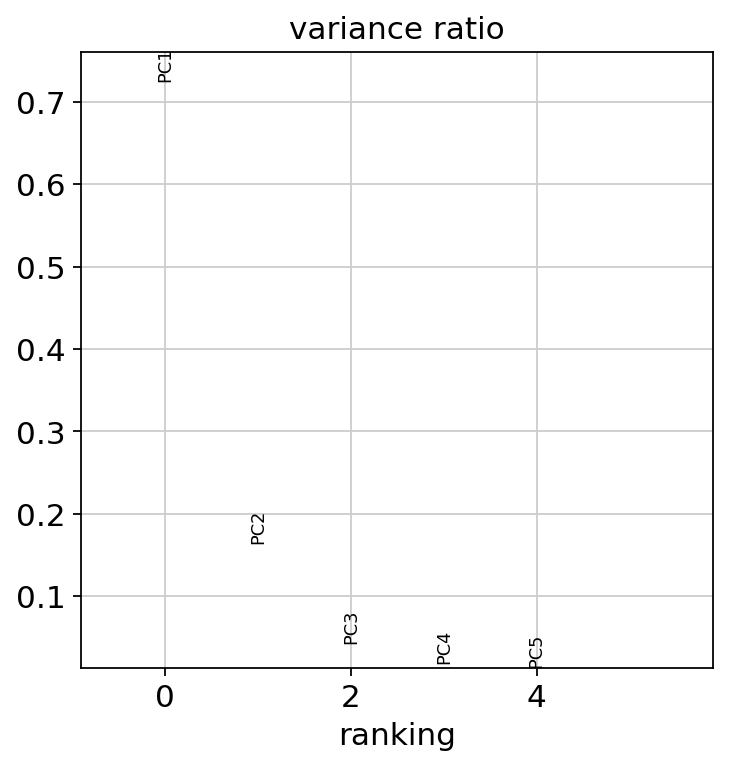

In [13]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.pca_variance_ratio(adata_bulk, n_pcs=5, log=False)

<Axes: title={'center': 'group'}, xlabel='PC1 (72.47000122070312%)', ylabel='PC2 (16.440000534057617%)'>

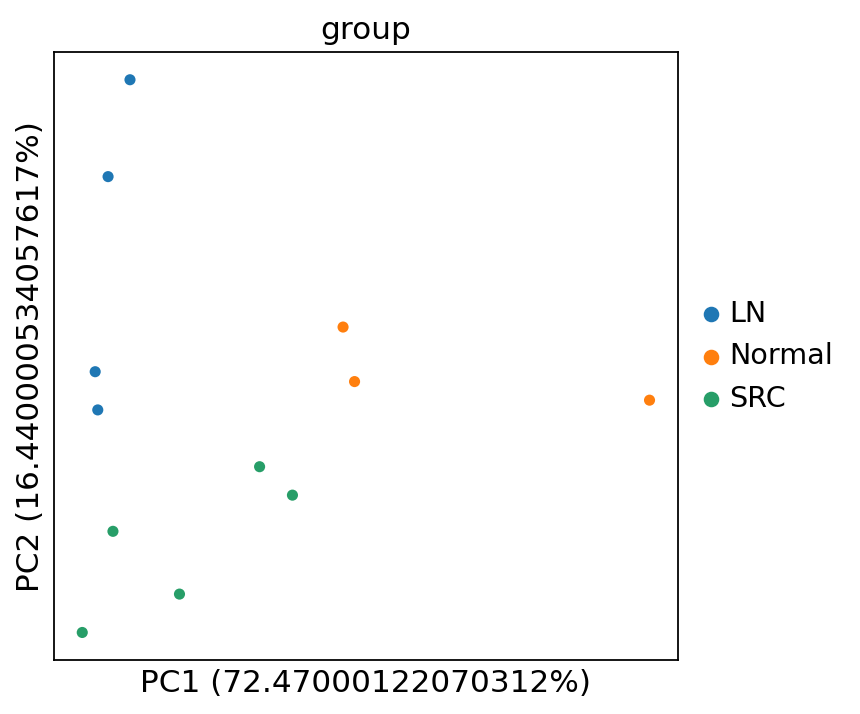

In [14]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.pca(adata_bulk, 
          color='group',
          size=100,
          annotate_var_explained=True, 
          show=False)

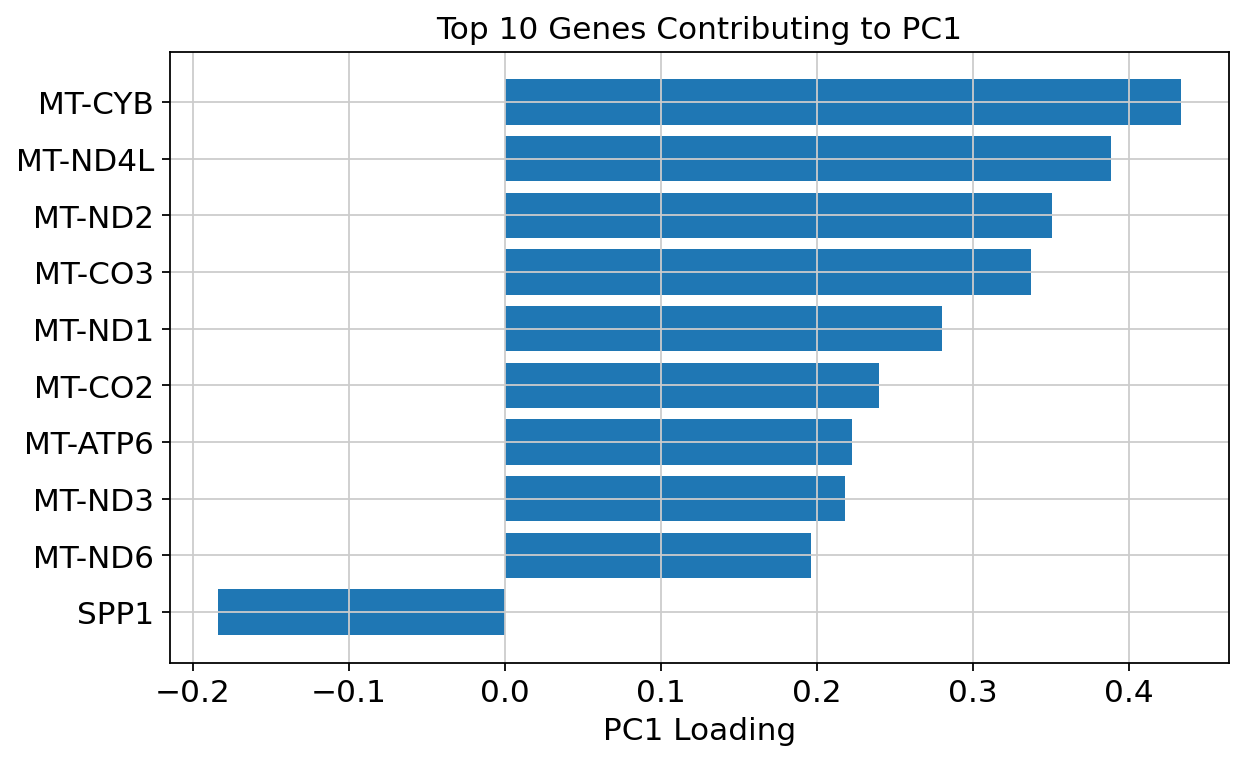

In [15]:
# Get top 10 genes for PC1
pc1 = adata_bulk.varm["PCs"][:, 0]
top_indices = np.argsort(np.abs(pc1))[::-1][:10]
top_genes = adata_bulk.var_names[top_indices]
top_values = pc1[top_indices]

# Plot
plt.figure(figsize=(8, 5))
plt.barh(top_genes[::-1], top_values[::-1])
plt.xlabel("PC1 Loading")
plt.title("Top 10 Genes Contributing to PC1")
plt.tight_layout()
plt.grid(True)
plt.show()

In [16]:
# remove MT- genes from adata
adata_bulk = adata_bulk[:, ~adata_bulk.var_names.str.startswith('MT-')].copy()

In [17]:
adata_bulk.X = adata_bulk.layers['counts'].copy()
sc.pp.normalize_total(adata_bulk, target_sum=1e6)
sc.tl.pca(adata_bulk, n_comps=5)

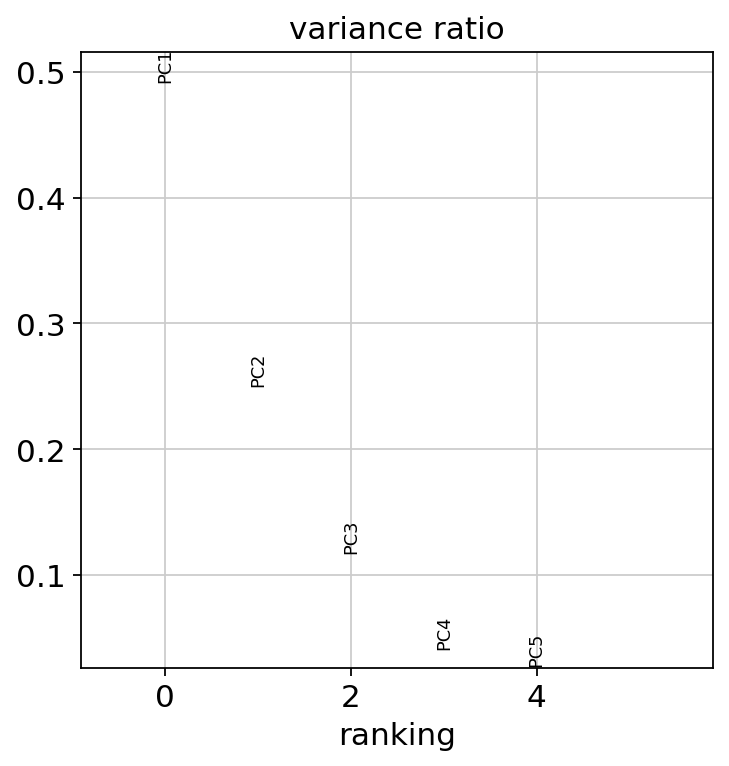

In [18]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.pca_variance_ratio(adata_bulk, n_pcs=5, log=False)

<Axes: title={'center': 'group'}, xlabel='PC1 (49.150001525878906%)', ylabel='PC2 (25.049999237060547%)'>

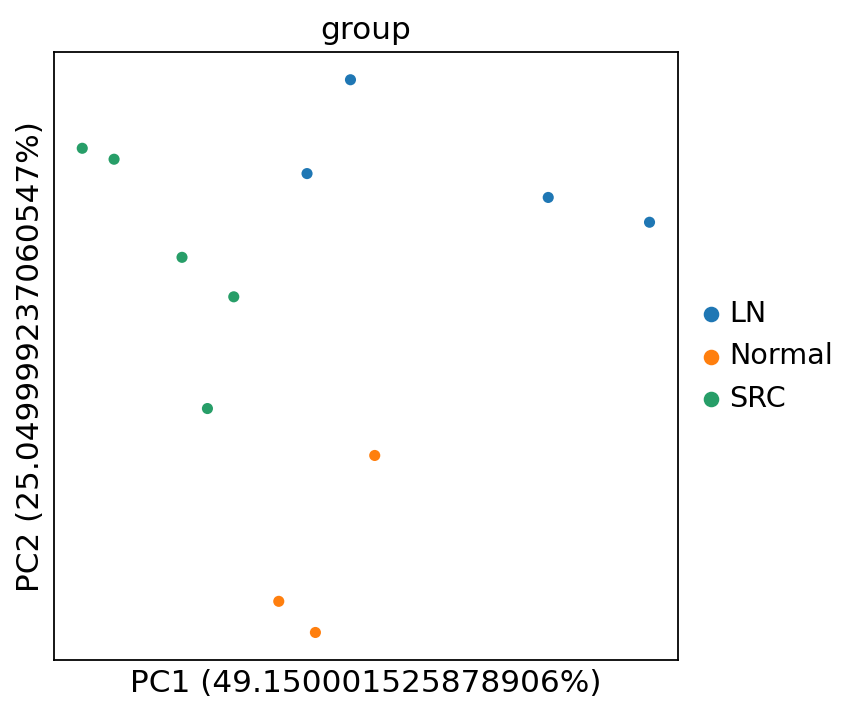

In [19]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.pca(adata_bulk, 
          color='group',
          size=100,
          annotate_var_explained=True, 
          show=False)

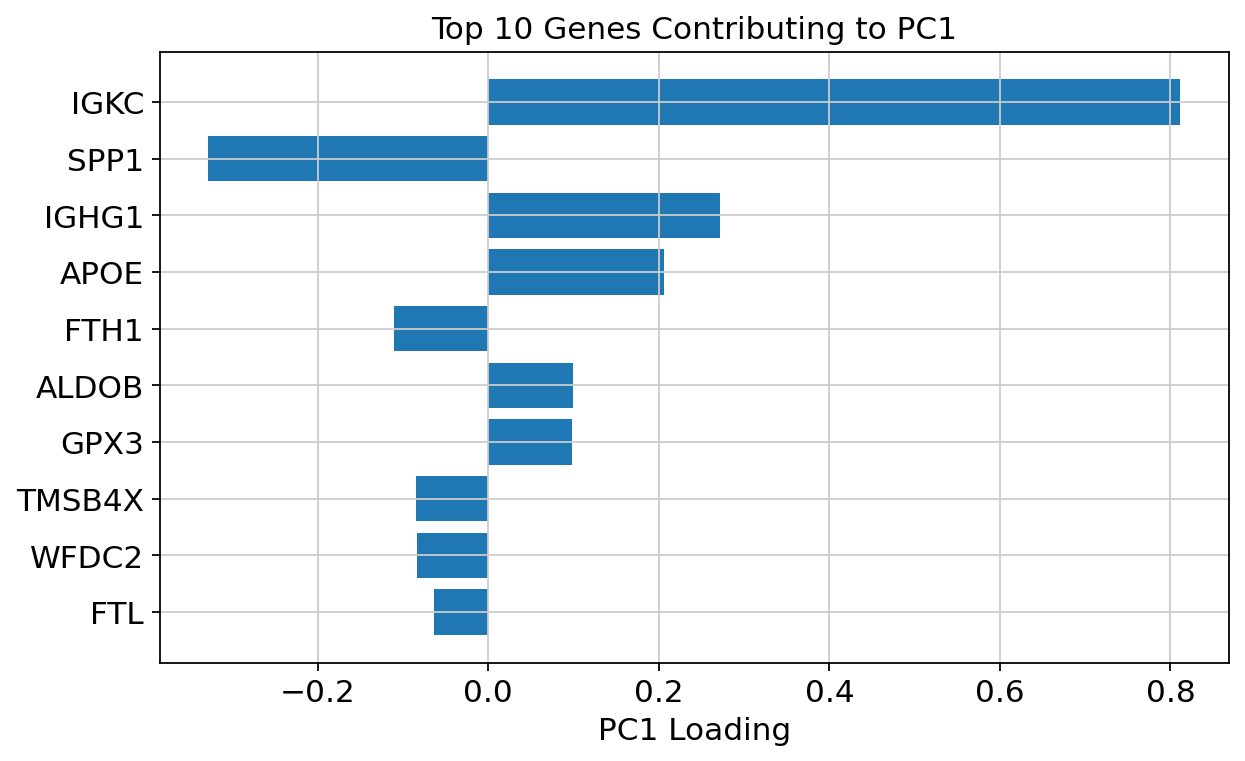

In [20]:
# Get top 10 genes for PC1
pc1 = adata_bulk.varm["PCs"][:, 0]
top_indices = np.argsort(np.abs(pc1))[::-1][:10]
top_genes = adata_bulk.var_names[top_indices]
top_values = pc1[top_indices]

# Plot
plt.figure(figsize=(8, 5))
plt.barh(top_genes[::-1], top_values[::-1])
plt.xlabel("PC1 Loading")
plt.title("Top 10 Genes Contributing to PC1")
plt.tight_layout()
plt.grid(True)
plt.show()

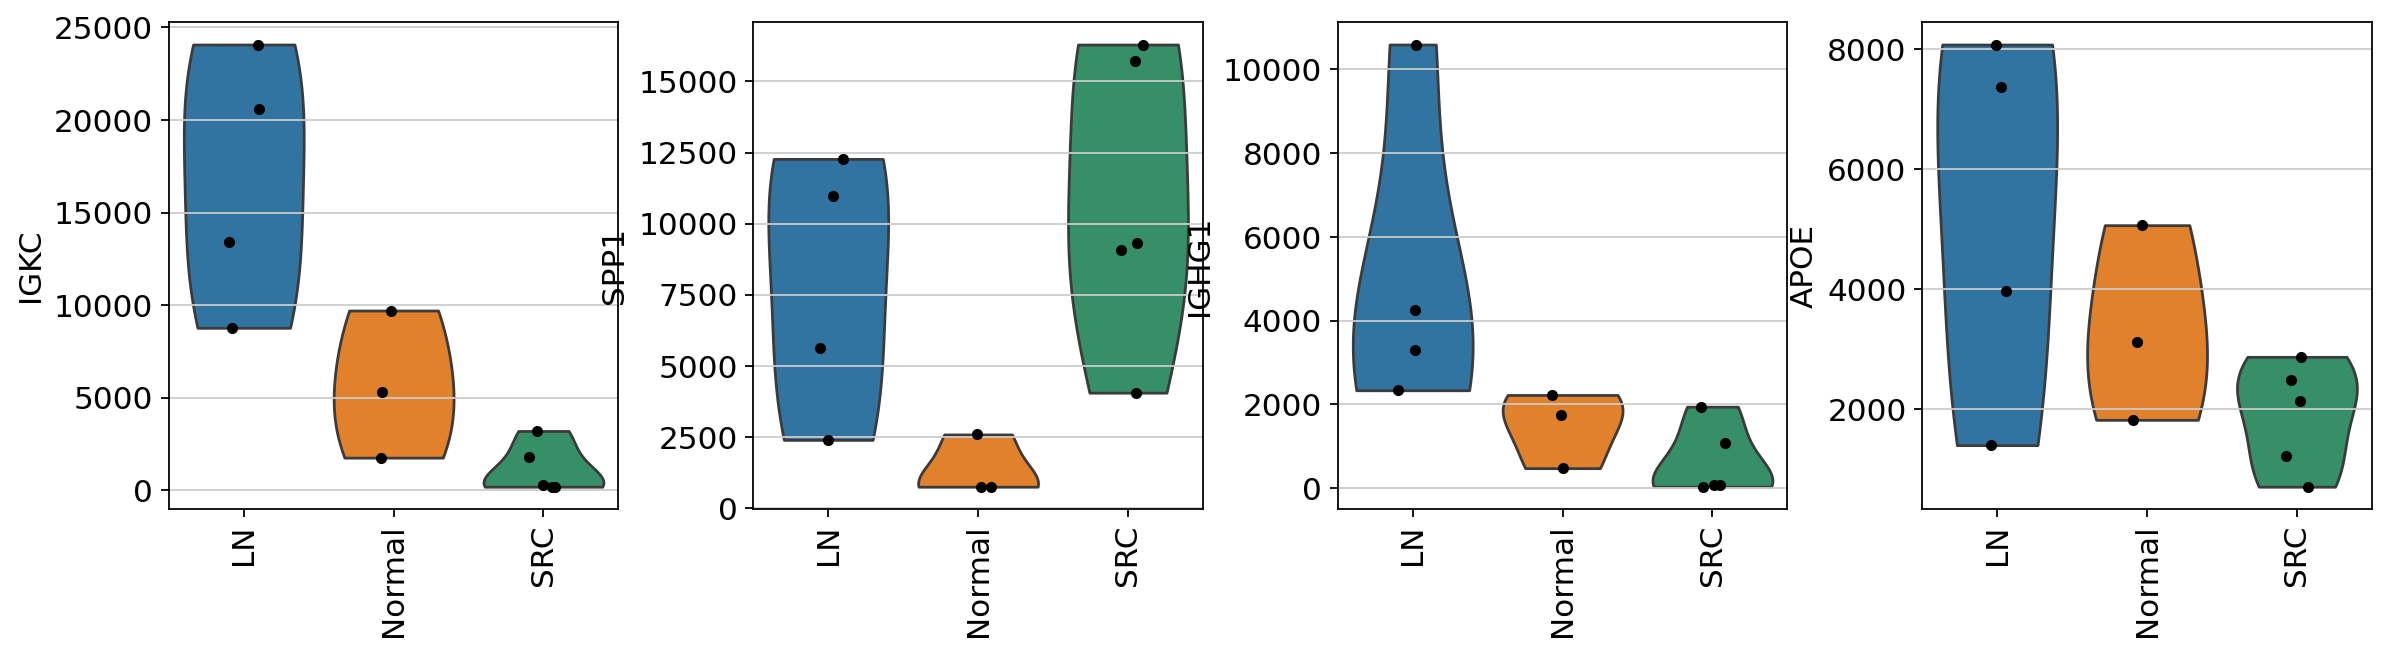

In [21]:
sc.set_figure_params(figsize=(4, 4))

sc.pl.violin(adata_bulk, keys=["IGKC", "SPP1", "IGHG1", "APOE"], 
             use_raw=False, groupby="group", size=5, rotation=90, multi_panel=True)

In [22]:
# perform DE analysis using DESeq2
df_counts = adata_bulk.to_df(layer="counts")
df_meta = adata_bulk.obs.copy()
df_meta = df_meta[["group"]]

In [23]:
df_counts.to_csv(f"{out_dir}/counts_bulk.csv")
df_meta.to_csv(f"{out_dir}/meta_bulk.csv")

adata_bulk.write_h5ad(f"{out_dir}/adata_bulk.h5ad")